# 01 · Exploración y limpieza de datos

**Proyecto:** Análisis de ventas de supermercados en Ecuador (Corporación Favorita, Kaggle)

En este notebook vamos a:

1. Cargar los 5 archivos CSV y entender **qué significa cada columna**.
2. Revisar la **calidad de los datos**: valores faltantes, fechas que faltan, tiendas que abrieron tarde, etc.
3. Entender y limpiar la tabla de **feriados**, sobre todo los **feriados trasladados**.
4. Guardar tablas limpias en `data/processed/` para usarlas en el notebook `02_preguntas_de_negocio.ipynb`.

> 💡 **Consejo para principiantes:** ejecuta las celdas en orden, de arriba hacia abajo (`Shift + Enter`).
> Si algo falla, vuelve a ejecutar desde la primera celda.

## Paso 1 · Importar librerías y definir rutas

- `pandas` es la librería para trabajar con tablas (llamadas *DataFrames*).
- Guardamos las rutas en variables para no escribirlas muchas veces.

In [1]:
from pathlib import Path
import pandas as pd

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

# Mostrar más columnas y números sin notación científica
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)

## Paso 2 · Cargar los archivos

Usamos `parse_dates=["date"]` para que pandas entienda la columna `date` como **fecha** y no como texto.
Así podremos sacar el año, el mes o el día de la semana fácilmente.

`train.csv` tiene ~3 millones de filas, así que puede tardar unos segundos.

In [2]:
train = pd.read_csv(RAW / "train.csv", parse_dates=["date"])
stores = pd.read_csv(RAW / "stores.csv")
oil = pd.read_csv(RAW / "oil.csv", parse_dates=["date"])
holidays = pd.read_csv(RAW / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(RAW / "transactions.csv", parse_dates=["date"])

for nombre, df in [("train", train), ("stores", stores), ("oil", oil),
                   ("holidays_events", holidays), ("transactions", transactions)]:
    print(f"{nombre:<16} {df.shape[0]:>10,} filas  x {df.shape[1]} columnas")

train             3,000,888 filas  x 6 columnas
stores                   54 filas  x 5 columnas
oil                   1,218 filas  x 2 columnas
holidays_events         350 filas  x 6 columnas
transactions         83,488 filas  x 3 columnas


## Paso 3 · ¿Qué significa cada columna?

### `train.csv` — la tabla principal (una fila = una familia de productos, en una tienda, en un día)

| Columna | Significado |
|---|---|
| `id` | Identificador de la fila (no aporta información para el análisis). |
| `date` | Fecha de la venta (2013-01-01 a 2017-08-15). |
| `store_nbr` | Número de tienda (1 a 54). Se une con `stores.csv`. |
| `family` | Familia o categoría de producto (33 en total: `GROCERY I`, `BEVERAGES`, `PRODUCE`…). |
| `sales` | Ventas totales de esa familia en esa tienda ese día. **No son dólares**: son unidades (puede tener decimales porque algunos productos se venden por kilo). |
| `onpromotion` | Cuántos productos de esa familia estaban en promoción ese día en esa tienda. |

In [3]:
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.00,0
1,1,2013-01-01,1,BABY CARE,0.00,0
2,2,2013-01-01,1,BEAUTY,0.00,0
3,3,2013-01-01,1,BEVERAGES,0.00,0
4,4,2013-01-01,1,BOOKS,0.00,0


### `stores.csv` — información de cada tienda

| Columna | Significado |
|---|---|
| `store_nbr` | Número de tienda (clave para unir con `train`). |
| `city` | Ciudad donde está la tienda. |
| `state` | Provincia. |
| `type` | Tipo de tienda (A, B, C, D, E). Kaggle no explica qué significa cada letra; lo descubriremos con los datos. |
| `cluster` | Grupo de tiendas parecidas (1 a 17), definido por la empresa. |

In [4]:
stores.head()

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


### `oil.csv` — precio diario del petróleo (WTI, en dólares por barril)

Ecuador es un país que depende mucho del petróleo, por eso Kaggle incluye este dato.

| Columna | Significado |
|---|---|
| `date` | Fecha. |
| `dcoilwtico` | Precio del barril de petróleo WTI. Tiene huecos en fines de semana y feriados (el mercado está cerrado). |

### `transactions.csv` — número de tickets (compras) por tienda y día

| Columna | Significado |
|---|---|
| `date` | Fecha. |
| `store_nbr` | Número de tienda. |
| `transactions` | Cantidad de compras realizadas (tickets de caja). |

### `holidays_events.csv` — feriados y eventos

| Columna | Significado |
|---|---|
| `date` | Fecha del feriado o evento. |
| `type` | `Holiday` (feriado), `Transfer` (día al que se movió un feriado), `Bridge` (puente: día extra libre), `Work Day` (día laborable para recuperar el puente, suele ser sábado), `Additional` (días que se añaden alrededor de un feriado, ej. Navidad-1), `Event` (eventos especiales: Mundial, Día de la Madre, terremoto…). |
| `locale` | Alcance: `National` (todo el país), `Regional` (una provincia) o `Local` (una ciudad). |
| `locale_name` | Nombre del lugar: `Ecuador`, la provincia o la ciudad. |
| `description` | Nombre del feriado. |
| `transferred` | `True` si el feriado **se trasladó** a otro día (ese día fue normal). |

In [5]:
holidays.head(10)

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


## Paso 4 · Revisar la calidad de los datos

Antes de analizar, siempre revisamos:

1. ¿Hay **valores faltantes** (`NaN`)?
2. ¿Los tipos de datos son correctos?
3. ¿Faltan fechas?
4. ¿Hay cosas raras (valores negativos, muchos ceros)?

In [6]:
for nombre, df in [("train", train), ("stores", stores), ("oil", oil),
                   ("holidays_events", holidays), ("transactions", transactions)]:
    print(nombre, "->", df.isna().sum().to_dict())

train -> {'id': 0, 'date': 0, 'store_nbr': 0, 'family': 0, 'sales': 0, 'onpromotion': 0}
stores -> {'store_nbr': 0, 'city': 0, 'state': 0, 'type': 0, 'cluster': 0}
oil -> {'date': 0, 'dcoilwtico': 43}
holidays_events -> {'date': 0, 'type': 0, 'locale': 0, 'locale_name': 0, 'description': 0, 'transferred': 0}
transactions -> {'date': 0, 'store_nbr': 0, 'transactions': 0}


Solo `oil.csv` tiene faltantes (43 días). Los trataremos en el Paso 6.

Ahora miramos el rango de fechas y si falta algún día en `train`:

In [7]:
print("Desde:", train["date"].min().date(), " Hasta:", train["date"].max().date())

todas_las_fechas = pd.date_range(train["date"].min(), train["date"].max(), freq="D")
fechas_faltantes = todas_las_fechas.difference(train["date"].unique())
print("Fechas que faltan:", list(fechas_faltantes.date))

Desde: 2013-01-01  Hasta: 2017-08-15


Fechas que faltan: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]


Faltan solo los **25 de diciembre**: las tiendas cierran en Navidad. No es un error, así que no hay que rellenarlos.

Revisemos los valores de `sales` y `onpromotion`:

In [8]:
print(train[["sales", "onpromotion"]].describe())
print()
print("Ventas negativas:", (train["sales"] < 0).sum())
print(f"Filas con ventas = 0: {(train['sales'] == 0).mean():.1%}")

             sales  onpromotion
count 3,000,888.00 3,000,888.00
mean        357.78         2.60
std       1,102.00        12.22
min           0.00         0.00
25%           0.00         0.00
50%          11.00         0.00
75%         195.85         0.00
max     124,717.00       741.00

Ventas negativas: 0
Filas con ventas = 0: 31.3%


- No hay ventas negativas.
- Casi **un tercio de las filas tiene ventas = 0**. Esto pasa porque algunas familias no se venden en ciertas tiendas,
  o porque una tienda todavía no había abierto. Veamos cuándo empezó a vender cada tienda:

In [9]:
primera_venta = (train[train["sales"] > 0]
                 .groupby("store_nbr")["date"].min()
                 .rename("primera_venta"))

tiendas_nuevas = primera_venta[primera_venta > "2013-01-31"].to_frame().join(stores.set_index("store_nbr"))
tiendas_nuevas

,primera_venta,city,state,type,cluster
store_nbr,,,,,
20,2015-02-13,Quito,Pichincha,B,6
21,2015-07-24,Santo Domingo,Santo Domingo de los Tsachilas,B,6
22,2015-10-09,Puyo,Pastaza,C,7
29,2015-03-20,Guayaquil,Guayas,E,10
36,2013-05-09,Libertad,Guayas,E,10
42,2015-08-21,Cuenca,Azuay,D,2
52,2017-04-20,Manta,Manabi,A,11
53,2014-05-29,Manta,Manabi,D,13


**8 tiendas abrieron después de enero de 2013** (la 52 recién en abril de 2017).

⚠️ **Por qué importa:** si comparamos ventas *totales* entre tiendas, las nuevas parecerán peores solo por haber
abierto tarde. Por eso, en el notebook 02 compararemos tiendas usando un periodo en el que la mayoría ya estaba abierta,
y usaremos **ventas promedio por día**.

Lo mismo pasa con las familias de productos: algunas empiezan a registrar ventas recién en 2014.

In [10]:
inicio_familia = train[train["sales"] > 0].groupby("family")["date"].min()
inicio_familia[inicio_familia > "2013-02-01"].sort_values()

family
PRODUCE                      2013-03-16
CELEBRATION                  2014-01-01
HOME AND KITCHEN I           2014-01-01
HOME AND KITCHEN II          2014-01-01
HOME CARE                    2014-01-01
MAGAZINES                    2014-01-01
PET SUPPLIES                 2014-01-01
PLAYERS AND ELECTRONICS      2014-01-01
LADIESWEAR                   2014-01-02
SCHOOL AND OFFICE SUPPLIES   2014-01-02
BABY CARE                    2014-03-01
BOOKS                        2016-10-08
Name: date, dtype: datetime64[us]

⚠️ Varias familias (`HOME CARE`, `CELEBRATION`, `PET SUPPLIES`…) empiezan el **1 de enero de 2014**.
Esto parece un cambio en el registro de datos, no productos realmente nuevos.
Consecuencia: **el gran salto de ventas entre 2013 y 2014 está inflado** por estas familias que antes no se registraban.
Lo tendremos en cuenta en las conclusiones.

También vemos que `onpromotion` está en 0 durante 2013: las promociones empiezan a registrarse en 2014.

In [11]:
train.groupby(train["date"].dt.year)["onpromotion"].sum()

date
2013          0
2014     459114
2015    1087275
2016    3514584
2017    2749649
Name: onpromotion, dtype: int64

## Paso 4b · ⚠️ Huecos de registro: el problema más importante del dataset

Un buen hábito es graficar las ventas totales **mes a mes** antes de sacar conclusiones. Mira lo que pasa:

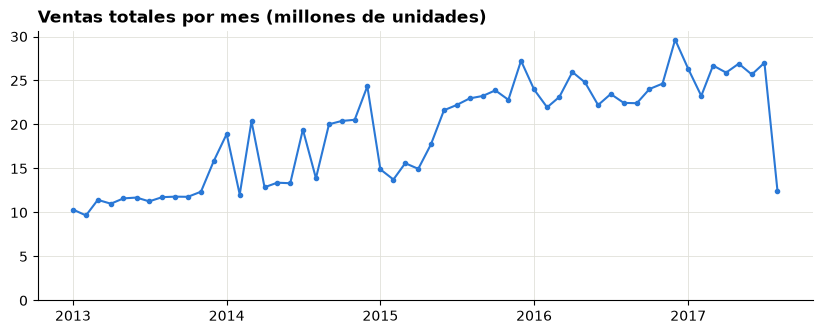

In [12]:
import matplotlib.pyplot as plt

total_mensual = train.set_index("date")["sales"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(total_mensual.index, total_mensual.values / 1e6, color="#2a78d6", marker="o", markersize=3)
ax.set_title("Ventas totales por mes (millones de unidades)", loc="left", fontweight="bold")
ax.set_ylim(0)
ax.grid(color="#e1e0d9", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Entre 2014 y mayo de 2015 las ventas **saltan arriba y abajo** de un mes a otro (≈13 M ↔ ≈20 M).
Eso no es comportamiento real de clientes: un supermercado no pierde un tercio de sus ventas en febrero y las
recupera en marzo. Veamos qué familias causan esos saltos:

In [13]:
mensual_familia = (train.set_index("date")
                   .groupby("family")["sales"].resample("MS").sum()
                   .unstack(level=0))

mensual_familia.loc["2014-01":"2014-10", ["GROCERY I", "BEVERAGES", "PRODUCE", "HOME CARE", "CELEBRATION"]] / 1e6

family,GROCERY I,BEVERAGES,PRODUCE,HOME CARE,CELEBRATION
date,,,,,
2014-01-01,4.94,4.15,3.24,0.44,0.02
2014-02-01,4.69,1.92,0.01,0.00,0.00
2014-03-01,5.55,4.43,3.35,0.43,0.02
2014-04-01,5.06,2.11,0.01,0.00,0.00
2014-05-01,5.32,2.08,0.01,0.00,0.00
2014-06-01,5.26,2.10,0.01,0.00,0.00
2014-07-01,5.29,4.18,3.22,0.43,0.02
2014-08-01,5.50,2.11,0.01,0.00,0.00
2014-09-01,5.35,4.30,3.39,0.43,0.02


Clarísimo: en febrero, abril, mayo, junio y agosto de 2014 (y en 2013 y enero–mayo de 2015), familias como
`PRODUCE` o `HOME CARE` **casi no tienen ventas registradas**, y `BEVERAGES` baja a la mitad. En cambio
`GROCERY I` es estable. Son **huecos en el registro de datos**, no meses malos.

### ¿Qué familias tienen huecos?

Regla sencilla: comparamos el promedio de los meses "sospechosos" de 2014 con el de sus meses vecinos.
Si una familia vende menos del 60% en los meses sospechosos, la marcamos como **familia con huecos**.

In [14]:
meses_sospechosos = ["2014-02", "2014-04", "2014-05", "2014-06", "2014-08"]
meses_vecinos = ["2014-01", "2014-03", "2014-07", "2014-09", "2014-10"]

calidad = pd.DataFrame({
    "ratio_sospechosos_vs_vecinos": mensual_familia.loc[meses_sospechosos].mean()
                                    / mensual_familia.loc[meses_vecinos].mean()
})
# BOOKS no tiene ventas en 2014 (empieza en oct-2016): también la marcamos
calidad["con_huecos"] = calidad["ratio_sospechosos_vs_vecinos"].fillna(0) < 0.6
calidad.sort_values("ratio_sospechosos_vs_vecinos")

,ratio_sospechosos_vs_vecinos,con_huecos
family,,
BABY CARE,0.00,True
CELEBRATION,0.00,True
HOME AND KITCHEN II,0.00,True
HOME AND KITCHEN I,0.00,True
PET SUPPLIES,0.00,True
MAGAZINES,0.00,True
LADIESWEAR,0.00,True
HOME CARE,0.00,True
SCHOOL AND OFFICE SUPPLIES,0.00,True


In [15]:
familias_con_huecos = calidad[calidad["con_huecos"]].index.tolist()
familias_completas = calidad[~calidad["con_huecos"]].index.tolist()
print(f"Familias con huecos ({len(familias_con_huecos)}):", familias_con_huecos)
print(f"Familias completas  ({len(familias_completas)}):", familias_completas)

Familias con huecos (13): ['BABY CARE', 'BEVERAGES', 'BOOKS', 'CELEBRATION', 'HOME AND KITCHEN I', 'HOME AND KITCHEN II', 'HOME CARE', 'LADIESWEAR', 'MAGAZINES', 'PET SUPPLIES', 'PLAYERS AND ELECTRONICS', 'PRODUCE', 'SCHOOL AND OFFICE SUPPLIES']
Familias completas  (20): ['AUTOMOTIVE', 'BEAUTY', 'BREAD/BAKERY', 'CLEANING', 'DAIRY', 'DELI', 'EGGS', 'FROZEN FOODS', 'GROCERY I', 'GROCERY II', 'HARDWARE', 'HOME APPLIANCES', 'LAWN AND GARDEN', 'LINGERIE', 'LIQUOR,WINE,BEER', 'MEATS', 'PERSONAL CARE', 'POULTRY', 'PREPARED FOODS', 'SEAFOOD']


La separación es muy clara: 12 familias tienen un ratio ≤ 0,48 (11 de ellas ≈ 0) y todas las demás están por
encima de 0,7.

**¿Desde cuándo los datos son confiables?** Volviendo al primer gráfico, a partir de **junio de 2015** la serie
deja de saltar. Comprobémoslo con la participación de las familias con huecos en el total:

In [16]:
peso_huecos = mensual_familia[familias_con_huecos].sum(axis=1) / mensual_familia.sum(axis=1) * 100
peso_huecos["2015-01":"2015-09"].round(1)

date
2015-01-01   16.60
2015-02-01   16.30
2015-03-01   15.30
2015-04-01   15.90
2015-05-01   22.70
2015-06-01   41.10
2015-07-01   40.20
2015-08-01   39.90
2015-09-01   41.90
Freq: MS, dtype: float64

Desde junio de 2015 esas familias ya pesan lo normal (~30% de las ventas) todos los meses.

### Decisión: cómo trabajaremos en el notebook 02

| Análisis | Datos que usamos | Por qué |
|---|---|---|
| Tendencia de largo plazo y estacionalidad 2013–2017 | Solo las **familias completas** | Son comparables en todos los meses. |
| Ranking y crecimiento de familias, promociones, días de la semana | **Periodo confiable: desde el 1-jun-2015** | Todas las familias se registran bien. |
| Tiendas y ciudades | Desde 2016 | Periodo confiable y casi todas las tiendas abiertas. |

> 💡 **Lección para el portafolio:** si hubiéramos sumado todo sin revisar, habríamos concluido que las ventas
> crecieron 41% en 2014 o que `PRODUCE` se disparó en 2015. Ambas cosas son, en gran parte, efecto de los huecos.
> Revisar la calidad de los datos **antes** de analizar es la parte más importante del trabajo de un analista.

In [17]:
PERIODO_CONFIABLE = "2015-06-01"

## Paso 5 · Feriados: cómo tratar los feriados trasladados

Esta es la parte más delicada del dataset. Veamos un ejemplo real:

In [18]:
holidays[holidays["description"].str.contains("Primer Grito de Independencia")
         & (holidays["date"].dt.year == 2016)]

,date,type,locale,locale_name,description,transferred
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
269,2016-08-12,Transfer,National,Ecuador,Traslado Primer Grito de Independencia,False


**Cómo leerlo:**

- El 10 de agosto de 2016 era oficialmente el feriado *Primer Grito de Independencia*, pero tiene `transferred = True`:
  el gobierno lo **movió**. Ese 10 de agosto la gente trabajó normalmente → **se trata como día normal**.
- El 12 de agosto aparece con `type = Transfer`: ese es el día que **realmente** fue libre → **se trata como feriado**.

### Reglas que vamos a aplicar

| Caso | ¿Cómo lo tratamos? |
|---|---|
| `type == "Holiday"` y `transferred == False` | Feriado ✅ |
| `type == "Holiday"` y `transferred == True` | **Día normal** ❌ (el feriado se movió a otra fecha) |
| `type == "Transfer"` | Feriado ✅ (es el día real de descanso) |
| `type == "Bridge"` | Feriado ✅ (puente, día extra libre) |
| `type == "Work Day"` | **Día normal** ❌ (día laborable para recuperar el puente) |
| `type == "Additional"` | Día adicional de feriado (ej. 24 de diciembre = `Navidad-1`) |
| `type == "Event"` | Evento especial (Mundial, Día de la Madre, terremoto…) |

Además, el **alcance** importa:

- `National` → afecta a **todas** las tiendas.
- `Regional` → solo a tiendas cuya provincia (`stores.state`) coincide con `locale_name`.
- `Local` → solo a tiendas cuya ciudad (`stores.city`) coincide con `locale_name`.

> Otro detalle: no confíes en la columna `description` para detectar traslados. Por ejemplo, el traslado de
> *Fundación de Cuenca* (2017-04-13) **no** dice "Traslado" en el texto, pero sí tiene `type = Transfer`.
> Usa siempre las columnas `type` y `transferred`.

In [19]:
# Todos los traslados del dataset: cada feriado movido aparece junto a su día real
holidays[(holidays["transferred"]) | (holidays["type"] == "Transfer")].sort_values("date")

,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
20,2012-10-12,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
73,2013-10-11,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
136,2014-10-10,Transfer,National,Ecuador,Traslado Independencia de Guayaquil,False
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
256,2016-05-27,Transfer,National,Ecuador,Traslado Batalla de Pichincha,False
265,2016-07-24,Transfer,Local,Guayaquil,Traslado Fundacion de Guayaquil,False
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True


Ahora creamos una columna nueva `tipo_dia` aplicando las reglas de la tabla.
Usamos una función normal de Python para que sea fácil de leer:

In [20]:
def clasificar_dia(fila):
    if fila["transferred"]:          # feriado movido a otra fecha -> ese día fue normal
        return "Dia normal"
    if fila["type"] == "Work Day":   # día laborable de recuperación
        return "Dia normal"
    if fila["type"] in ["Holiday", "Transfer", "Bridge"]:
        return "Feriado"
    if fila["type"] == "Additional":
        return "Adicional"
    return "Evento"                  # type == "Event"

feriados = holidays.copy()
feriados["tipo_dia"] = feriados.apply(clasificar_dia, axis=1)
feriados["tipo_dia"].value_counts()

tipo_dia
Feriado       226
Evento         56
Adicional      51
Dia normal     17
Name: count, dtype: int64

Una misma fecha puede tener varias filas (por ejemplo, un feriado local en Machala y otro en Latacunga el mismo día).
Para el análisis de **ventas totales del país** usaremos solo los registros **nacionales**, y nos quedamos con
una fila por fecha, priorizando `Feriado` > `Adicional` > `Evento`:

In [21]:
prioridad = {"Feriado": 1, "Adicional": 2, "Evento": 3, "Dia normal": 4}

feriados_nacionales = (feriados[feriados["locale"] == "National"]
                       .assign(prioridad=lambda d: d["tipo_dia"].map(prioridad))
                       .sort_values(["date", "prioridad"])
                       .drop_duplicates(subset="date", keep="first")
                       [["date", "tipo_dia", "type", "description"]])

print("Fechas nacionales únicas:", len(feriados_nacionales))
feriados_nacionales.head()

Fechas nacionales únicas: 168


,date,tipo_dia,type,description
14,2012-08-10,Feriado,Holiday,Primer Grito de Independencia
19,2012-10-09,Dia normal,Holiday,Independencia de Guayaquil
20,2012-10-12,Feriado,Transfer,Traslado Independencia de Guayaquil
21,2012-11-02,Feriado,Holiday,Dia de Difuntos
22,2012-11-03,Feriado,Holiday,Independencia de Cuenca


### Bonus: feriados por tienda

Si en el futuro quieres analizar tiendas individuales (o hacer un modelo de predicción), necesitas saber qué
feriado aplica a **cada tienda**. Así se cruzan los feriados regionales y locales con la tabla de tiendas:

In [22]:
dias_especiales = feriados[feriados["tipo_dia"] != "Dia normal"]

nacional = dias_especiales[dias_especiales["locale"] == "National"].merge(stores[["store_nbr"]], how="cross")
regional = dias_especiales[dias_especiales["locale"] == "Regional"].merge(
    stores[["store_nbr", "state"]], left_on="locale_name", right_on="state")
local = dias_especiales[dias_especiales["locale"] == "Local"].merge(
    stores[["store_nbr", "city"]], left_on="locale_name", right_on="city")

feriados_por_tienda = (pd.concat([nacional, regional, local])
                       [["date", "store_nbr", "tipo_dia", "locale", "description"]]
                       .sort_values(["date", "store_nbr"])
                       .reset_index(drop=True))
print(feriados_por_tienda.shape)
feriados_por_tienda.sample(5, random_state=1)

(9218, 5)


,date,store_nbr,tipo_dia,locale,description
3427,2014-12-01,26,Evento,National,Cyber Monday
1653,2013-12-23,32,Adicional,National,Navidad-2
5289,2016-02-08,32,Feriado,National,Carnaval
1924,2014-01-01,33,Feriado,National,Primer dia del ano
5897,2016-04-24,37,Evento,National,Terremoto Manabi+8


## Paso 6 · Petróleo: rellenar los días faltantes

El precio del petróleo no se publica fines de semana ni feriados. Lo más razonable es usar el **último precio
conocido** (*forward fill*, `ffill`): si el viernes costaba 50, el sábado y domingo también se consideran 50.

El primer día (2013-01-01) no tiene un valor anterior, así que lo rellenamos con el siguiente (`bfill`).

In [23]:
calendario = pd.DataFrame({"date": pd.date_range(oil["date"].min(), oil["date"].max(), freq="D")})
petroleo = calendario.merge(oil, on="date", how="left")
petroleo["precio_petroleo"] = petroleo["dcoilwtico"].ffill().bfill()
petroleo = petroleo[["date", "precio_petroleo"]]

print("Faltantes después de rellenar:", petroleo["precio_petroleo"].isna().sum())
petroleo.head()

Faltantes después de rellenar: 0


,date,precio_petroleo
0,2013-01-01,93.14
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12


## Paso 7 · Crear la tabla diaria y guardar los datos procesados

Juntamos todo a nivel **país y día**: ventas totales, productos en promoción, transacciones, petróleo y feriados.

In [24]:
ventas_diarias = (train.groupby("date")
                  .agg(ventas=("sales", "sum"), productos_en_promo=("onpromotion", "sum"))
                  .reset_index())

# Ventas solo de las familias completas (sin huecos), para comparar todo el periodo 2013-2017
completas = (train[train["family"].isin(familias_completas)]
             .groupby("date")["sales"].sum().rename("ventas_familias_completas").reset_index())
ventas_diarias = ventas_diarias.merge(completas, on="date", how="left")

tickets = transactions.groupby("date")["transactions"].sum().rename("transacciones").reset_index()

ventas_diarias = (ventas_diarias
                  .merge(tickets, on="date", how="left")
                  .merge(petroleo, on="date", how="left")
                  .merge(feriados_nacionales[["date", "tipo_dia", "description"]], on="date", how="left"))

ventas_diarias["tipo_dia"] = ventas_diarias["tipo_dia"].fillna("Dia normal")
ventas_diarias = ventas_diarias.rename(columns={"description": "descripcion_feriado"})
ventas_diarias.head()

,date,ventas,productos_en_promo,ventas_familias_completas,transacciones,precio_petroleo,tipo_dia,descripcion_feriado
0,2013-01-01,"2,511.62",0,"1,701.62",770.00,93.14,Feriado,Primer dia del ano
1,2013-01-02,"496,092.42",0,"424,000.42","93,215.00",93.14,Dia normal,NaN
2,2013-01-03,"361,461.23",0,"309,356.23","78,504.00",92.97,Dia normal,NaN
3,2013-01-04,"354,459.68",0,"300,292.68","78,494.00",93.12,Dia normal,NaN
4,2013-01-05,"477,350.12",0,"399,532.12","93,573.00",93.12,Dia normal,Recupero puente Navidad


También guardamos ventas **mensuales por tienda y familia**, una tabla mucho más liviana que `train.csv`
(~100 mil filas en vez de 3 millones), ideal para las preguntas sobre familias y tiendas.

In [25]:
ventas_mensuales = (train
                    .assign(mes=train["date"].dt.to_period("M").dt.to_timestamp())
                    .groupby(["mes", "store_nbr", "family"], as_index=False)
                    .agg(ventas=("sales", "sum"), productos_en_promo=("onpromotion", "sum"))
                    .merge(stores, on="store_nbr", how="left"))
print(ventas_mensuales.shape)
ventas_mensuales.head()

(99792, 9)


,mes,store_nbr,family,ventas,productos_en_promo,city,state,type,cluster
0,2013-01-01,1,AUTOMOTIVE,68.00,0,Quito,Pichincha,D,13
1,2013-01-01,1,BABY CARE,0.00,0,Quito,Pichincha,D,13
2,2013-01-01,1,BEAUTY,45.00,0,Quito,Pichincha,D,13
3,2013-01-01,1,BEVERAGES,"28,777.00",0,Quito,Pichincha,D,13
4,2013-01-01,1,BOOKS,0.00,0,Quito,Pichincha,D,13


In [26]:
ventas_diarias.to_csv(PROCESSED / "ventas_diarias.csv", index=False)
ventas_mensuales.to_csv(PROCESSED / "ventas_mensuales_tienda_familia.csv", index=False)
feriados.to_csv(PROCESSED / "feriados_limpios.csv", index=False)
calidad.to_csv(PROCESSED / "calidad_familias.csv", index_label="family")
feriados_por_tienda.to_csv(PROCESSED / "feriados_por_tienda.csv", index=False)

for archivo in sorted(PROCESSED.glob("*.csv")):
    print(f"{archivo.name:<40} {archivo.stat().st_size / 1e6:6.1f} MB")

calidad_familias.csv                        0.0 MB
feriados_limpios.csv                        0.0 MB
feriados_por_tienda.csv                     0.5 MB
ventas_diarias.csv                          0.1 MB
ventas_mensuales_tienda_familia.csv         5.8 MB


## Resumen de lo que aprendimos

- Los datos van del **1-ene-2013 al 15-ago-2017**: 54 tiendas, 33 familias de productos.
- `sales` son **unidades**, no dólares.
- Faltan los 25 de diciembre (tiendas cerradas): es normal.
- **8 tiendas abrieron tarde** → para comparar tiendas usamos ventas promedio por día.
- **Huecos de registro:** hasta mayo de 2015, 12 familias (entre ellas `PRODUCE`, `BEVERAGES` y `HOME CARE`) faltan
  total o parcialmente en muchos meses. Usaremos las **familias completas** para tendencias largas y el
  **periodo confiable (desde jun-2015)** para lo demás.
- Las promociones se registran desde 2014.
- **Feriados trasladados:** el día con `transferred = True` fue un día normal; el día con `type = Transfer` es el
  feriado real. `Work Day` también es un día normal.
- El petróleo se rellenó con el último precio conocido.

➡️ Siguiente paso: `02_preguntas_de_negocio.ipynb`